In [1]:

import numpy as np
import matplotlib.pyplot as plt
import heapq
import time

# Create a 10x10 grid
grid = np.zeros((10, 10), dtype=int)

# Add obstacles
grid[1, 2:7] = 1
grid[5, 1:5] = 1
grid[7, 5:9] = 1

# Define start and goal
start = (0, 0)
goal = (9, 9)

print("Environment created successfully!")
print("Start:", start)
print("Goal:", goal)


Environment created successfully!
Start: (0, 0)
Goal: (9, 9)


In [2]:

def heuristic(a, b):
    # Manhattan distance
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def astar(grid, start, goal):

    # Priority queue
    open_list = []

    heapq.heappush(
        open_list,
        (0, start)
    )

    # Track previous nodes
    came_from = {}

    # Cost from start
    g_score = {start: 0}

    # Possible movements: up, down, left, right
    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    while open_list:

        # Get the node with lowest priority
        current_f, current = heapq.heappop(open_list)

        # Check if goal is reached
        if current == goal:

            path = [current]

            while current in came_from:
                current = came_from[current]
                path.append(current)

            return path[::-1]

        # Explore neighboring cells
        for dr, dc in directions:

            neighbor = (
                current[0] + dr,
                current[1] + dc
            )

            row, col = neighbor

            # Check grid boundaries
            if not (0 <= row < grid.shape[0]
                    and 0 <= col < grid.shape[1]):
                continue

            # Skip obstacles
            if grid[row, col] == 1:
                continue

            # Calculate new path cost
            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):

                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = (
                    tentative_g
                    + heuristic(neighbor, goal)
                )

                heapq.heappush(
                    open_list,
                    (f_score, neighbor)
                )

    return None


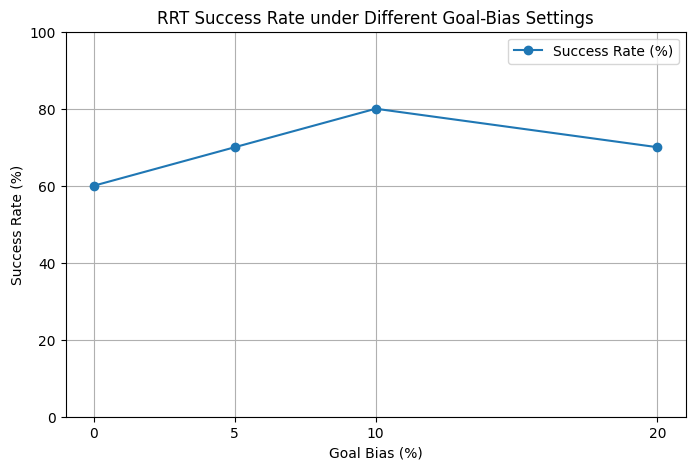

In [102]:
import matplotlib.pyplot as plt

# Goal-bias experimental results
goal_bias = [0, 5, 10, 20]

success_rate = [60, 70, 80, 70]
planning_time = [15.76, 12.84, 10.91, 15.34]

plt.figure(figsize=(8, 5))

plt.plot(goal_bias, success_rate, marker='o', label='Success Rate (%)')

plt.xlabel('Goal Bias (%)')
plt.ylabel('Success Rate (%)')
plt.title('RRT Success Rate under Different Goal-Bias Settings')

plt.xticks(goal_bias)
plt.ylim(0, 100)
plt.grid(True)
plt.legend()

plt.show()

In [3]:

start_time = time.perf_counter()

path = astar(grid, start, goal)

end_time = time.perf_counter()

planning_time = end_time - start_time

if path:
    print("Path found!")
    print("Path:", path)
    print("Number of steps:", len(path) - 1)
    print("Planning time:", planning_time, "seconds")
else:
    print("No path found!")


Path found!
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]
Number of steps: 18
Planning time: 0.0004012890000240077 seconds


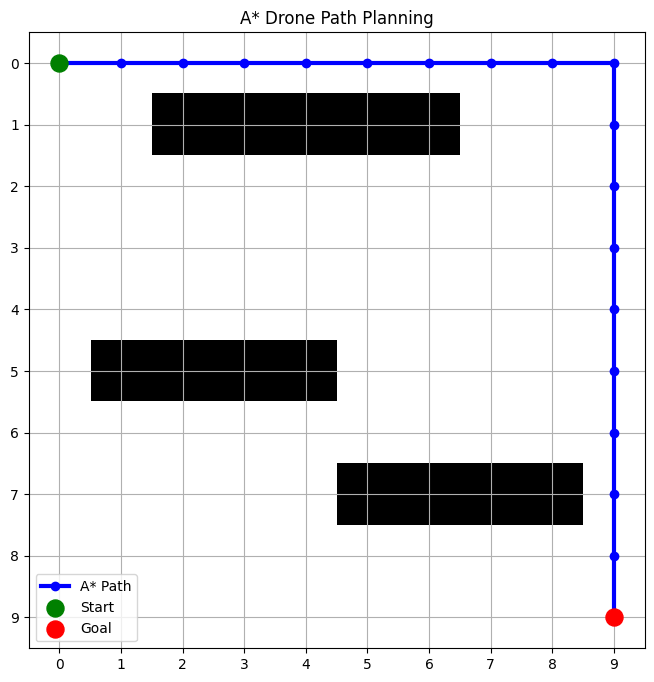

In [4]:

plt.figure(figsize=(8, 8))

plt.imshow(grid, cmap="Greys", origin="upper")

# Draw the calculated path
if path:
    path_rows = [point[0] for point in path]
    path_cols = [point[1] for point in path]

    plt.plot(
        path_cols,
        path_rows,
        color="blue",
        linewidth=3,
        marker="o",
        label="A* Path"
    )

# Draw start and goal
plt.scatter(
    start[1], start[0],
    color="green",
    s=150,
    label="Start",
    zorder=3
)

plt.scatter(
    goal[1], goal[0],
    color="red",
    s=150,
    label="Goal",
    zorder=3
)

plt.xticks(range(10))
plt.yticks(range(10))
plt.grid(True)
plt.legend()
plt.title("A* Drone Path Planning")

plt.show()


Experiment 1: A* Pathfinding — Initial Results

Date:  22 November 2026

The experiment evaluated the A* algorithm's ability to find an optimal path in a 10 × 10 grid containing static obstacles, from the starting position (0, 0) to the goal (9, 9). The algorithm successfully generated a collision-free path along the top row and rightmost column, achieving the shortest possible distance of 18 steps (19 nodes), with zero collisions. This confirms that the implemented A* algorithm can effectively perform optimal grid-based pathfinding while avoiding obstacles. Further testing is required to evaluate its performance in more complex environments.

In [6]:
def is_free(position, grid):
  row, col=position
  return grid[row, col]==0

In [10]:
print(is_free((0, 0), grid))
print(is_free((2, 3), grid))

True
True


In [11]:
print("Cell (2,3):", grid[2,3])
print("Cell (5,3):", grid[5,3])
print("Cell (0,3):", grid[0,3])

Cell (2,3): 0
Cell (5,3): 1
Cell (0,3): 0


(2,3)- 0- Free
(5,3)- 1- Obstacle
(0,3)-0- Free

In [12]:
print(is_free((2,3),grid))
print(is_free((5,3),grid))
print(is_free((0,3), grid))

True
False
True


In [13]:
def is_inside(position, grid):
  row, col=position
  rows, cols=grid.shape
  return 0<= row < rows and 0 <=col <cols

In [14]:
print(is_inside((0, 0), grid))
print(is_inside((9, 9), grid))
print(is_inside((-1, 0), grid))
print(is_inside((10,5), grid))

True
True
False
False


In [15]:
directions = [
    (-1,0), #UP
    (1,0), #DOWN
    (0,-1), #LEFT
    (0,1), #RIGHT
]

In [16]:
print(directions)

[(-1, 0), (1, 0), (0, -1), (0, 1)]


In [17]:
def get_neighbours(position, grid):

    row, col = position
    neighbours = []

    for dr, dc in directions:

        new_row = row + dr
        new_col = col + dc

        new_position = (new_row, new_col)

        if is_inside(new_position, grid) and is_free(new_position, grid):
            neighbours.append(new_position)

    return neighbours


In [18]:
current_position = (0, 0)
result = get_neighbours(current_position, grid)
print(result)

[(1, 0), (0, 1)]


In [19]:
current_position = (5, 3)
result = get_neighbours(current_position, grid)
print(result)

[(4, 3), (6, 3)]


In [20]:
def get_cost(current, neighbour):
    return 1

In [21]:
print(get_cost((5, 3), (5, 4)))

1


In [22]:
print(get_cost((0, 0), (0, 1)))
print(get_cost((0, 0), (1, 0)))
print(get_cost((5, 3), (6, 3)))

1
1
1


In [23]:
def heuristic(position, goal):
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])

In [24]:
print(heuristic((2, 3), (9, 9)))

13


In [25]:
print(heuristic(start, goal))

18


def astar() - create a pathfinding functions
heapq.heappush- basically adds the queue to prioritize - QUEUE WITH PRIORITIZATION

In [26]:
def astar(grid, start, goal):
    open_set = []
    heapq.heappush(open_set, (0, start))
    came_from = {}
    g_score = {start: 0}
    f_score = {start: heuristic(start, goal)}
    heapq.heappush(open_set, (f_score[start], start))

In [27]:
print(heuristic(start, goal))

18


In [28]:
def astar(grid, start, goal):
    open_set = []

    came_from = {}

    g_score = {start: 0}

    f_score = {start: heuristic(start, goal)}

    heapq.heappush(open_set, (f_score[start], start))

    while open_set:
        current_priority, current = heapq.heappop(open_set)

        if current == goal:
            return reconstruct_path(came_from, current)

In [29]:

def astar(grid, start, goal):
    open_set = []

    came_from = {}

    g_score = {start: 0}

    f_score = {start: heuristic(start, goal)}

    heapq.heappush(open_set, (f_score[start], start))

    while open_set:
        current_priority, current = heapq.heappop(open_set)

        if current == goal:
            return reconstruct_path(came_from, current)

        for neighbour in get_neighbours(current, grid):
            tentative_g_score = g_score[current] + get_cost(current, neighbour)

            if tentative_g_score < g_score.get(neighbour, float("inf")):
                came_from[neighbour] = current

                g_score[neighbour] = tentative_g_score

                f_score[neighbour] = (
                    tentative_g_score + heuristic(neighbour, goal)
                )

                heapq.heappush(
                    open_set,
                    (f_score[neighbour], neighbour)
                )

    return None


In [30]:

def reconstruct_path(came_from, current):
    path = [current]

    while current in came_from:
        current = came_from[current]
        path.append(current)

    path.reverse()

    return path


In [31]:
path = astar(grid, start, goal)
print("Path:", path)
print("Number of steps:", len(path) - 1)


Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]
Number of steps: 18


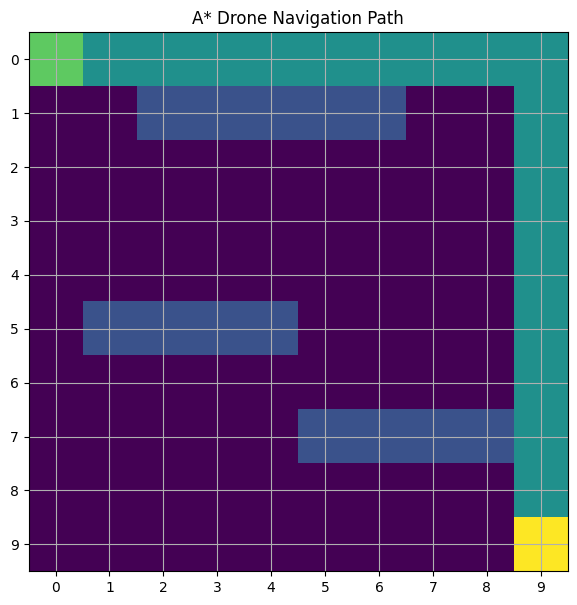

In [32]:

def visualize_path(grid, path, start, goal):
    display_grid = grid.copy()

    for row, col in path:
        display_grid[row, col] = 2

    display_grid[start] = 3
    display_grid[goal] = 4

    plt.figure(figsize=(7, 7))
    plt.imshow(display_grid, cmap="viridis")

    plt.xticks(range(grid.shape[1]))
    plt.yticks(range(grid.shape[0]))
    plt.grid(True)

    plt.title("A* Drone Navigation Path")
    plt.show()


visualize_path(grid, path, start, goal)


The visualization shows the path calculated by the A* (A-star) algorithm for a drone navigating through a 10×10 grid environment. The drone starts at the top-left corner (0, 0), marked in green, and its destination is the bottom-right corner (9, 9), marked in yellow. The blue areas represent obstacles that the drone must avoid, while the turquoise path shows the route selected by the algorithm. A* successfully finds a collision-free path by moving horizontally across the top row and then vertically down the rightmost column. The algorithm uses the Manhattan Distance heuristic to estimate the distance to the goal and selects the most promising cells during its search. The resulting path contains 18 movements, demonstrating that A* can find a valid shortest path in this grid environment while avoiding obstacles.

In [33]:
# Measure A* execution time
start_time = time.perf_counter()
path = astar(grid, start, goal)
end_time = time.perf_counter()
planning_time = end_time - start_time
print("Path found:", path is not None)
print("Path length:", len(path) - 1 if path else "No path")
print("Planning time:", planning_time, "seconds")

Path found: True
Path length: 18
Planning time: 0.00043946999994659564 seconds


In [34]:

def astar(grid, start, goal):
    open_set = []

    came_from = {}

    g_score = {start: 0}

    f_score = {start: heuristic(start, goal)}

    heapq.heappush(open_set, (f_score[start], start))

    explored_nodes = 0

    while open_set:
        current_priority, current = heapq.heappop(open_set)

        explored_nodes += 1

        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, explored_nodes

        for neighbour in get_neighbours(current, grid):
            tentative_g_score = (
                g_score[current] + get_cost(current, neighbour)
            )

            if tentative_g_score < g_score.get(neighbour, float("inf")):
                came_from[neighbour] = current

                g_score[neighbour] = tentative_g_score

                f_score[neighbour] = (
                    tentative_g_score + heuristic(neighbour, goal)
                )

                heapq.heappush(
                    open_set,
                    (f_score[neighbour], neighbour)
                )

    return None, explored_nodes


In [35]:

start_time = time.perf_counter()

path, explored_nodes = astar(grid, start, goal)

end_time = time.perf_counter()

planning_time = end_time - start_time

print("Path found:", path is not None)
print("Path length:", len(path) - 1 if path else "No path")
print("Explored nodes:", explored_nodes)
print("Planning time:", planning_time, "seconds")


Path found: True
Path length: 18
Explored nodes: 87
Planning time: 0.0007124099997781741 seconds


In [36]:
import time

number_of_runs = 10

planning_times = []
path_lengths = []
explored_nodes_list = []
successful_runs = 0

for run in range(number_of_runs):

    start_time = time.perf_counter()
    path, explored_nodes = astar(grid, start, goal)
    end_time = time.perf_counter()
    planning_time = end_time - start_time
    planning_times.append(planning_time)
    explored_nodes_list.append(explored_nodes)
    if path is not None:
        successful_runs += 1
        path_lengths.append(len(path) - 1)
average_time = sum(planning_times) / number_of_runs
average_explored_nodes = sum(explored_nodes_list) / number_of_runs
success_rate = (successful_runs / number_of_runs) * 100

if path_lengths:
    average_path_length = sum(path_lengths) / len(path_lengths)
else:
    average_path_length = 0

print("Number of runs:", number_of_runs)
print("Successful runs:", successful_runs)
print("Success rate:", success_rate, "%")
print("Average path length:", average_path_length)
print("Average explored nodes:", average_explored_nodes)
print("Average planning time:", average_time, "seconds")

Number of runs: 10
Successful runs: 10
Success rate: 100.0 %
Average path length: 18.0
Average explored nodes: 87.0
Average planning time: 0.0004936860998896008 seconds


In [37]:
def check_collision(path, grid):
 for position in path:
        if not is_free(position, grid):
            return True


In [38]:
def check_collision(path, grid):
    for position in path:
        if not is_free(position, grid):
            return True
    return False

In [39]:
path, explored_nodes = astar(grid, start, goal)

collision = check_collision(path, grid)

print("Collision detected:", collision)

Collision detected: False


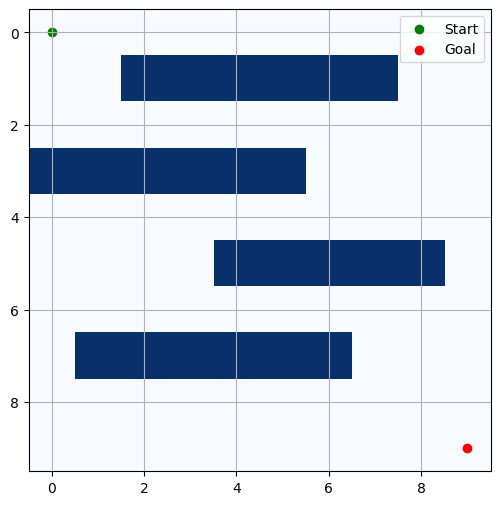

In [40]:
grid_2 = np.zeros((10, 10), dtype=int)
grid_2[1, 2:8] = 1
grid_2[3, 0:6] = 1
grid_2[5, 4:9] = 1
grid_2[7, 1:7] = 1

start_2 = (0, 0)
goal_2 = (9, 9)

plt.figure(figsize=(6, 6))
plt.imshow(grid_2, cmap="Blues")

plt.scatter(start_2[1], start_2[0], color="green", label="Start")
plt.scatter(goal_2[1], goal_2[0], color="red", label="Goal")

plt.legend()
plt.grid(True)
plt.show()

In [41]:
start_time = time.perf_counter()

path_2, explored_nodes_2 = astar(grid_2, start_2, goal_2)

end_time = time.perf_counter()

planning_time_2 = end_time - start_time

print("Path found:", path_2 is not None)

if path_2 is not None:
    print("Path length:", len(path_2) - 1)
    print("Explored nodes:", explored_nodes_2)
    print("Planning time:", planning_time_2, "seconds")
    print("Collision detected:", check_collision(path_2, grid_2))
else:
    print("No valid path found.")

Path found: True
Path length: 18
Explored nodes: 37
Planning time: 0.00025603900030546356 seconds
Collision detected: False


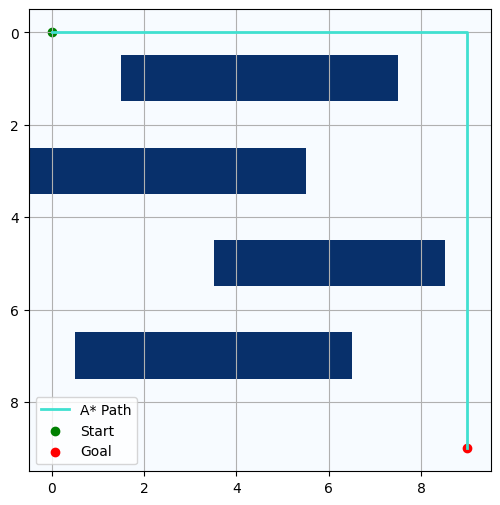

In [42]:
plt.figure(figsize=(6, 6))
plt.imshow(grid_2, cmap="Blues")

if path_2 is not None:
    path_rows = [position[0] for position in path_2]
    path_cols = [position[1] for position in path_2]

    plt.plot(path_cols, path_rows, color="turquoise", linewidth=2, label="A* Path")

plt.scatter(start_2[1], start_2[0], color="green", label="Start")
plt.scatter(goal_2[1], goal_2[0], color="red", label="Goal")

plt.legend()
plt.grid(True)
plt.show()

In [43]:
results = [
    {
        "Map": "Map 1",
        "Success": True,
        "Path Length": 18,
        "Explored Nodes": 87,
        "Planning Time (ms)": 0.436,
        "Collision": False
    },
    {
        "Map": "Map 2",
        "Success": True,
        "Path Length": 18,
        "Explored Nodes": 37,
        "Planning Time (ms)": planning_time_2 * 1000,
        "Collision": False
    }
]

import pandas as pd

results_df = pd.DataFrame(results)

results_df

,Map,Success,Path Length,Explored Nodes,Planning Time (ms),Collision
0,Map 1,True,18,87,0.436000,False
1,Map 2,True,18,37,0.256039,False


In [44]:
import random
import math

random.seed(42)

print("RRT is starting!")

RRT is starting!


In [45]:
random_point = (
    random.uniform(0, 9),
    random.uniform(0, 9)
)

print("Random point:", random_point)

Random point: (5.754841186120954, 0.22509679700400242)


In [46]:
start = (0, 0)

tree = [start]

print("RRT tree:", tree)

RRT tree: [(0, 0)]


In [47]:
distance = math.sqrt(
    (random_point[0] - tree[0][0]) ** 2 +
    (random_point[1] - tree[0][1]) ** 2
)

print("Distance:", distance)

Distance: 5.7592417595978285


In [48]:
step_size = 1.0

print("Step size:", step_size)

Step size: 1.0


In [49]:
nearest_node = tree[0]

new_x = nearest_node[0] + (step_size / distance) * (random_point[0] - nearest_node[0])
new_y = nearest_node[1] + (step_size / distance) * (random_point[1] - nearest_node[1])

new_node = (new_x, new_y)

print("New node:", new_node)

New node: (0.9992359109652689, 0.0390844500717263)


In [50]:
row = int(round(new_node[1]))
col = int(round(new_node[0]))

if grid_2[row, col] == 0:
    print("New node is collision-free!")
else:
    print("Collision detected!")

New node is collision-free!


In [51]:
tree.append(new_node)

print("Updated RRT tree:", tree)

Updated RRT tree: [(0, 0), (0.9992359109652689, 0.0390844500717263)]


In [52]:
parents = [-1, 0]

print("Parents:", parents)

Parents: [-1, 0]


In [53]:
goal = (9, 9)

max_iterations = 500

goal_threshold = 1.0

print("Start:", start)
print("Goal:", goal)
print("Max iterations:", max_iterations)
print("Goal threshold:", goal_threshold)

Start: (0, 0)
Goal: (9, 9)
Max iterations: 500
Goal threshold: 1.0


In [54]:
def find_nearest_node(tree, random_point):
    nearest_node = tree[0]
    min_distance = float("inf")

    for node in tree:
        distance = math.sqrt(
            (random_point[0] - node[0]) ** 2 +
            (random_point[1] - node[1]) ** 2
        )

        if distance < min_distance:
            min_distance = distance
            nearest_node = node

    return nearest_node


nearest_node = find_nearest_node(tree, random_point)

print("Random point:", random_point)
print("Nearest node:", nearest_node)

Random point: (5.754841186120954, 0.22509679700400242)
Nearest node: (0.9992359109652689, 0.0390844500717263)


In [55]:
def steer(nearest_node, random_point, step_size):
    distance = math.sqrt(
        (random_point[0] - nearest_node[0]) ** 2 +
        (random_point[1] - nearest_node[1]) ** 2
    )

    if distance <= step_size:
        return random_point

    new_x = nearest_node[0] + (step_size / distance) * (random_point[0] - nearest_node[0])
    new_y = nearest_node[1] + (step_size / distance) * (random_point[1] - nearest_node[1])

    return (new_x, new_y)

In [56]:
new_node = steer(nearest_node, random_point, step_size)

print("New node:", new_node)

New node: (1.9984718219305377, 0.0781689001434526)


In [57]:
def check_line_collision(start_node, end_node, grid):
    distance = math.sqrt(
        (end_node[0] - start_node[0]) ** 2 +
        (end_node[1] - start_node[1]) ** 2
    )

    steps = int(distance * 10) + 1

    for i in range(steps + 1):
        t = i / steps

        x = start_node[0] + t * (end_node[0] - start_node[0])
        y = start_node[1] + t * (end_node[1] - start_node[1])

        row = int(round(y))
        col = int(round(x))

        if grid[row, col] == 1:
            return True

    return False

In [58]:
collision = check_line_collision(nearest_node, new_node, grid_2)

print("Collision:", collision)

Collision: False


In [59]:
def add_node(tree, parents, new_node, parent_index):
    tree.append(new_node)
    parents.append(parent_index)

In [60]:
parent_index = tree.index(nearest_node)

add_node(tree, parents, new_node, parent_index)

print("Tree size:", len(tree))
print("Parents:", parents)

Tree size: 3
Parents: [-1, 0, 1]


In [61]:
goal_reached = False

print("Goal reached:", goal_reached)

Goal reached: False


In [62]:
goal_reached = False

In [63]:
def get_random_point(grid):
    while True:
        x = random.uniform(0, 9)
        y = random.uniform(0, 9)

        row = int(round(y))
        col = int(round(x))

        if grid[row, col] == 0:
            return (x, y)

In [64]:
random_point = get_random_point(grid_2)

print("Free random point:", random_point)

Free random point: (2.4752638653220735, 2.008896643339405)


In [65]:
# Reset the RRT tree
tree = [start]
parents = [-1]
goal_reached = False

# Main RRT loop
for iteration in range(max_iterations):

    # 1. Generate a random point
    random_point = get_random_point(grid_2)

    # 2. Find the nearest node
    nearest_node = find_nearest_node(tree, random_point)

    # 3. Find the nearest node index
    parent_index = tree.index(nearest_node)

    # 4. Create a new node
    new_node = steer(nearest_node, random_point, step_size)

    # 5. Check for collision
    collision = check_line_collision(nearest_node, new_node, grid_2)

    if not collision:

        # 6. Add the new node to the tree
        add_node(tree, parents, new_node, parent_index)

        # 7. Check distance to goal
        goal_distance = math.sqrt(
            (goal[0] - new_node[0]) ** 2 +
            (goal[1] - new_node[1]) ** 2
        )

        # 8. Try to connect to goal
        if goal_distance <= goal_threshold:

            if not check_line_collision(new_node, goal, grid_2):
                tree.append(goal)
                parents.append(len(tree) - 2)
                goal_reached = True
                break

print("Goal reached:", goal_reached)
print("Iterations:", iteration + 1)
print("Tree size:", len(tree))

Goal reached: True
Iterations: 301
Tree size: 134


In [66]:
def reconstruct_rrt_path(tree, parents):
    path = []
    current_index = len(tree) - 1

    while current_index != -1:
        path.append(tree[current_index])
        current_index = parents[current_index]

    path.reverse()
    return path


rrt_path = reconstruct_rrt_path(tree, parents)

print("RRT path:", rrt_path)
print("Path length:", len(rrt_path) - 1)

RRT path: [(0, 0), (0.7363563347588766, 0.676593931587088), (1.0394508144343573, 1.629554443040868), (1.8398211620089504, 2.2290603285193384), (2.8329168803390377, 2.346367166489032), (3.7086663239700077, 1.8636012687911456), (4.525767191255248, 2.4400959978925556), (5.052313207468357, 2.3646744767064174), (6.052311088271352, 2.366733211638289), (6.75011720558683, 1.6504465213828463), (7.26747297989979, 1.7136892292568993), (7.75505282717512, 2.2379070052825707), (8.012585827164937, 2.2159381300976237), (8.70200193643525, 2.5121249344968426), (8.999170456582883, 3.1496430934816555), (8.623555543853064, 3.569889973649646), (8.76612110138793, 4.55967533513201), (8.76865437992464, 4.980230701187475), (8.71604257553622, 5.978845741149819), (7.876971956998413, 6.522868256406847), (8.405132343439949, 7.372012888488996), (7.913936296318285, 7.776242409857293), (8.211661368620181, 8.730894064296141), (9, 9)]
Path length: 23


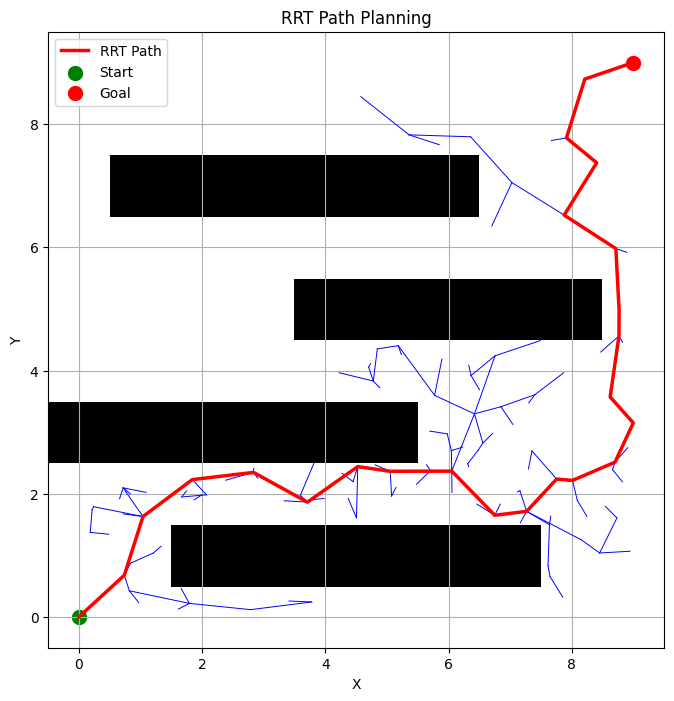

In [67]:
plt.figure(figsize=(8, 8))

# Draw obstacles
plt.imshow(grid_2, cmap="Greys", origin="lower")

# Draw RRT tree
for i in range(1, len(tree)):
    parent_index = parents[i]

    x_values = [tree[parent_index][0], tree[i][0]]
    y_values = [tree[parent_index][1], tree[i][1]]

    plt.plot(x_values, y_values, "b-", linewidth=0.7)

# Draw final path
path_x = [point[0] for point in rrt_path]
path_y = [point[1] for point in rrt_path]

plt.plot(path_x, path_y, "r-", linewidth=2.5, label="RRT Path")

# Mark start and goal
plt.scatter(start[0], start[1], color="green", s=100, label="Start")
plt.scatter(goal[0], goal[1], color="red", s=100, label="Goal")

plt.title("RRT Path Planning")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid()
plt.show()

In [68]:
path_length = 0

for i in range(len(rrt_path) - 1):
    x1, y1 = rrt_path[i]
    x2, y2 = rrt_path[i + 1]

    distance = math.sqrt(
        (x2 - x1) ** 2 +
        (y2 - y1) ** 2
    )

    path_length += distance

print("Total path length:", path_length)

Total path length: 18.93458855679535


In [69]:
start_time = time.perf_counter()

# Run the RRT algorithm here

planning_time = time.perf_counter() - start_time

print("Planning time:", planning_time)
print("Planning time (ms):", planning_time * 1000)

Planning time: 3.766999998333631e-05
Planning time (ms): 0.03766999998333631


In [70]:
# Reset the random generator
random.seed(42)

# Reset the RRT tree
tree = [start]
parents = [-1]
goal_reached = False

# Start measuring time
start_time = time.perf_counter()

# Run RRT
for iteration in range(max_iterations):

    random_point = get_random_point(grid_2)

    nearest_node = find_nearest_node(tree, random_point)

    parent_index = tree.index(nearest_node)

    new_node = steer(nearest_node, random_point, step_size)

    collision = check_line_collision(nearest_node, new_node, grid_2)

    if not collision:
        add_node(tree, parents, new_node, parent_index)

        goal_distance = math.sqrt(
            (goal[0] - new_node[0]) ** 2 +
            (goal[1] - new_node[1]) ** 2
        )

        if goal_distance <= goal_threshold:

            if not check_line_collision(new_node, goal, grid_2):
                tree.append(goal)
                parents.append(len(tree) - 2)
                goal_reached = True
                break

# Stop measuring time
planning_time = time.perf_counter() - start_time

print("Goal reached:", goal_reached)
print("Iterations:", iteration + 1)
print("Tree size:", len(tree))
print("Planning time (seconds):", planning_time)
print("Planning time (ms):", planning_time * 1000)

Goal reached: True
Iterations: 303
Tree size: 135
Planning time (seconds): 0.005641979999836622
Planning time (ms): 5.641979999836622


In [71]:
rrt_path = reconstruct_rrt_path(tree, parents)

path_collision = False

for i in range(len(rrt_path) - 1):
    if check_line_collision(
        rrt_path[i],
        rrt_path[i + 1],
        grid_2
    ):
        path_collision = True
        break

print("Path collision:", path_collision)

Path collision: False


In [72]:
results = []

for seed in range(10):

    random.seed(seed)

    tree = [start]
    parents = [-1]
    goal_reached = False

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        random_point = get_random_point(grid_2)
        nearest_node = find_nearest_node(tree, random_point)
        parent_index = tree.index(nearest_node)
        new_node = steer(nearest_node, random_point, step_size)

        if not check_line_collision(nearest_node, new_node, grid_2):

            add_node(tree, parents, new_node, parent_index)

            goal_distance = math.dist(new_node, goal)

            if goal_distance <= goal_threshold:
                if not check_line_collision(new_node, goal, grid_2):
                    tree.append(goal)
                    parents.append(len(tree) - 2)
                    goal_reached = True
                    break

    planning_time = time.perf_counter() - start_time

    results.append({
        "success": goal_reached,
        "iterations": iteration + 1,
        "nodes": len(tree),
        "time_ms": planning_time * 1000
    })

print(results)

[{'success': True, 'iterations': 187, 'nodes': 107, 'time_ms': 3.1600199999957113}, {'success': True, 'iterations': 297, 'nodes': 231, 'time_ms': 8.075540000390902}, {'success': True, 'iterations': 330, 'nodes': 224, 'time_ms': 9.518959999695653}, {'success': True, 'iterations': 332, 'nodes': 197, 'time_ms': 8.377379000194196}, {'success': True, 'iterations': 115, 'nodes': 58, 'time_ms': 1.3100999999551277}, {'success': True, 'iterations': 271, 'nodes': 151, 'time_ms': 4.713089999768272}, {'success': True, 'iterations': 315, 'nodes': 189, 'time_ms': 6.959490000099322}, {'success': True, 'iterations': 313, 'nodes': 168, 'time_ms': 5.752289999691129}, {'success': True, 'iterations': 372, 'nodes': 227, 'time_ms': 8.783380000295438}, {'success': True, 'iterations': 424, 'nodes': 216, 'time_ms': 9.38055999995413}]


In [73]:
results = []

for seed in range(10):

    random.seed(seed)

    tree = [start]
    parents = [-1]
    goal_reached = False

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        random_point = get_random_point(grid_2)
        nearest_node = find_nearest_node(tree, random_point)
        parent_index = tree.index(nearest_node)
        new_node = steer(nearest_node, random_point, step_size)

        if not check_line_collision(nearest_node, new_node, grid_2):

            add_node(tree, parents, new_node, parent_index)

            goal_distance = math.dist(new_node, goal)

            if goal_distance <= goal_threshold:
                if not check_line_collision(new_node, goal, grid_2):
                    tree.append(goal)
                    parents.append(len(tree) - 2)
                    goal_reached = True
                    break

    planning_time = time.perf_counter() - start_time

    if goal_reached:
        path = reconstruct_rrt_path(tree, parents)

        path_length = 0

        for i in range(len(path) - 1):
            path_length += math.dist(path[i], path[i + 1])

        collision_free = True

        for i in range(len(path) - 1):
            if check_line_collision(path[i], path[i + 1], grid_2):
                collision_free = False
                break

    else:
        path_length = None
        collision_free = False

    results.append({
        "success": goal_reached,
        "iterations": iteration + 1,
        "nodes": len(tree),
        "time_ms": planning_time * 1000,
        "path_length": path_length,
        "collision_free": collision_free
    })

print(results)

[{'success': True, 'iterations': 187, 'nodes': 107, 'time_ms': 5.054430000200227, 'path_length': 21.425311009769402, 'collision_free': True}, {'success': True, 'iterations': 297, 'nodes': 231, 'time_ms': 9.021509999911359, 'path_length': 17.822236428733962, 'collision_free': True}, {'success': True, 'iterations': 330, 'nodes': 224, 'time_ms': 8.18040000012843, 'path_length': 20.77768914033442, 'collision_free': True}, {'success': True, 'iterations': 332, 'nodes': 197, 'time_ms': 7.221370000024763, 'path_length': 18.0604926857274, 'collision_free': True}, {'success': True, 'iterations': 115, 'nodes': 58, 'time_ms': 1.2862300000051619, 'path_length': 17.235158535113705, 'collision_free': True}, {'success': True, 'iterations': 271, 'nodes': 151, 'time_ms': 7.752150000214897, 'path_length': 16.66953939453611, 'collision_free': True}, {'success': True, 'iterations': 315, 'nodes': 189, 'time_ms': 12.793510000392416, 'path_length': 18.894401542329053, 'collision_free': True}, {'success': True

In [74]:
astar_results = []

for run in range(10):

    start_time = time.perf_counter()

    path, explored_nodes = astar(grid_2, start_2, goal_2)

    planning_time = time.perf_counter() - start_time

    success = path is not None

    if success:
        path_length = len(path) - 1
        collision_free = not check_collision(path, grid_2)
    else:
        path_length = None
        collision_free = False

    astar_results.append({
        "success": success,
        "path_length": path_length,
        "explored_nodes": explored_nodes,
        "time_ms": planning_time * 1000,
        "collision_free": collision_free
    })

print(astar_results)

[{'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.17114999991463264, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.14241000008041738, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.18414000032862532, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.1301010001952818, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.1440089999960037, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.13249899984657532, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.1483600003666652, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.125480999940919, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 37, 'time_ms': 0.1251

In [75]:
grid_3 = np.zeros((10, 10), dtype=int)

grid_3[0:10, 2] = 1
grid_3[1, 2] = 0

grid_3[0:10, 5] = 1
grid_3[4, 5] = 0

grid_3[0:10, 8] = 1
grid_3[7, 8] = 0

start_3 = (0, 0)
goal_3 = (9, 9)

In [76]:
astar_results_3 = []

for run in range(10):

    start_time = time.perf_counter()

    path, explored_nodes = astar(grid_3, start_3, goal_3)

    planning_time = time.perf_counter() - start_time

    success = path is not None

    if success:
        path_length = len(path) - 1
        collision_free = not check_collision(path, grid_3)
    else:
        path_length = None
        collision_free = False

    astar_results_3.append({
        "success": success,
        "path_length": path_length,
        "explored_nodes": explored_nodes,
        "time_ms": planning_time * 1000,
        "collision_free": collision_free
    })

print(astar_results_3)
goal_bias = 0.1

[{'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.25240000013582176, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.2814399999806483, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.20801999971808982, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.21306000007825787, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.2013899998019042, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.20501999961197725, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.22984999986874755, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.20979999999326537, 'collision_free': True}, {'success': True, 'path_length': 18, 'explored_nodes': 56, 'time_ms': 0.2

In [77]:
rrt_results_3 = []

for seed in range(10):

    random.seed(seed)

    tree = [start_3]
    parents = [-1]
    goal_reached = False

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        random_point = get_random_point(grid_3)
        nearest_node = find_nearest_node(tree, random_point)
        parent_index = tree.index(nearest_node)
        new_node = steer(nearest_node, random_point, step_size)

        if not check_line_collision(nearest_node, new_node, grid_3):

            add_node(tree, parents, new_node, parent_index)

            goal_distance = math.dist(new_node, goal_3)

            if goal_distance <= goal_threshold:
                if not check_line_collision(new_node, goal_3, grid_3):
                    tree.append(goal_3)
                    parents.append(len(tree) - 2)
                    goal_reached = True
                    break

    planning_time = time.perf_counter() - start_time

    if goal_reached:
        path = reconstruct_rrt_path(tree, parents)

        path_length = 0

        for i in range(len(path) - 1):
            path_length += math.dist(path[i], path[i + 1])

        collision_free = True

        for i in range(len(path) - 1):
            if check_line_collision(path[i], path[i + 1], grid_3):
                collision_free = False
                break

    else:
        path_length = None
        collision_free = False

    rrt_results_3.append({
        "success": goal_reached,
        "iterations": iteration + 1,
        "nodes": len(tree),
        "time_ms": planning_time * 1000,
        "path_length": path_length,
        "collision_free": collision_free
    })

print(rrt_results_3)

[{'success': True, 'iterations': 268, 'nodes': 221, 'time_ms': 7.679340000322554, 'path_length': 16.286113418685563, 'collision_free': True}, {'success': False, 'iterations': 500, 'nodes': 448, 'time_ms': 27.73025999977108, 'path_length': None, 'collision_free': False}, {'success': True, 'iterations': 220, 'nodes': 201, 'time_ms': 6.4083899997058325, 'path_length': 15.782733288903994, 'collision_free': True}, {'success': True, 'iterations': 360, 'nodes': 318, 'time_ms': 13.83386999987124, 'path_length': 15.408762649074776, 'collision_free': True}, {'success': True, 'iterations': 116, 'nodes': 100, 'time_ms': 1.9827900005111587, 'path_length': 15.936145784061628, 'collision_free': True}, {'success': False, 'iterations': 500, 'nodes': 444, 'time_ms': 24.866790000487526, 'path_length': None, 'collision_free': False}, {'success': True, 'iterations': 161, 'nodes': 135, 'time_ms': 2.971869999782939, 'path_length': 18.997060521020817, 'collision_free': True}, {'success': False, 'iterations': 

In [79]:
step_size = 1.0
max_iterations = 500
goal_threshold = 1.0
goal_bias = 0.1

In [80]:
# Goal Bias RRT parameters

goal_bias = 0.1
step_size = 1.0
max_iterations = 500
goal_threshold = 1.0

# Initialize the tree

tree = [start_3]
parents = [-1]
goal_reached = False

# Start measuring planning time

start_time = time.perf_counter()

# RRT main loop

for iteration in range(max_iterations):

    # Choose goal or random point

    if random.random() < goal_bias:
        random_point = goal_3
    else:
        random_point = get_random_point(grid_3)

    # Find nearest node

    nearest_node = find_nearest_node(tree, random_point)
    parent_index = tree.index(nearest_node)

    # Generate a new node

    new_node = steer(nearest_node, random_point, step_size)

    # Check collision

    if not check_line_collision(nearest_node, new_node, grid_3):

        add_node(tree, parents, new_node, parent_index)

        # Check distance to goal

        goal_distance = math.dist(new_node, goal_3)

        if goal_distance <= goal_threshold:

            if not check_line_collision(new_node, goal_3, grid_3):

                tree.append(goal_3)
                parents.append(len(tree) - 2)

                goal_reached = True
                break

# Calculate planning time

planning_time = time.perf_counter() - start_time

# Print results

print("Goal reached:", goal_reached)
print("Iterations:", iteration + 1)
print("Tree size:", len(tree))
print("Planning time:", planning_time * 1000, "ms")

Goal reached: True
Iterations: 170
Tree size: 116
Planning time: 3.4687199995460105 ms


In [81]:
if goal_reached:

    rrt_path_3 = reconstruct_rrt_path(tree, parents)

    path_length = 0

    for i in range(len(rrt_path_3) - 1):

        path_length += math.dist(
            rrt_path_3[i],
            rrt_path_3[i + 1]
        )

    print("Path length:", path_length)

else:

    rrt_path_3 = None
    print("No path found")

Path length: 15.991951570709734


In [82]:
if rrt_path_3 is not None:

    path_collision = False

    for i in range(len(rrt_path_3) - 1):

        if check_line_collision(
            rrt_path_3[i],
            rrt_path_3[i + 1],
            grid_3
        ):
            path_collision = True
            break

    print("Path collision:", path_collision)

Path collision: False


In [83]:
goal_bias_results_3 = []

for seed in range(10):

    random.seed(seed)

    tree = [start_3]
    parents = [-1]
    goal_reached = False

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        # Goal Bias selection
        if random.random() < goal_bias:
            random_point = goal_3
        else:
            random_point = get_random_point(grid_3)

        # Find nearest node
        nearest_node = find_nearest_node(tree, random_point)
        parent_index = tree.index(nearest_node)

        # Generate new node
        new_node = steer(nearest_node, random_point, step_size)

        # Check collision
        if not check_line_collision(nearest_node, new_node, grid_3):

            add_node(tree, parents, new_node, parent_index)

            goal_distance = math.dist(new_node, goal_3)

            if goal_distance <= goal_threshold:

                if not check_line_collision(new_node, goal_3, grid_3):
                    tree.append(goal_3)
                    parents.append(len(tree) - 2)
                    goal_reached = True
                    break

    planning_time = time.perf_counter() - start_time

    # Calculate path metrics
    if goal_reached:

        path = reconstruct_rrt_path(tree, parents)

        path_length = 0

        for i in range(len(path) - 1):
            path_length += math.dist(path[i], path[i + 1])

        collision_free = True

        for i in range(len(path) - 1):
            if check_line_collision(path[i], path[i + 1], grid_3):
                collision_free = False
                break

    else:
        path_length = None
        collision_free = False

    goal_bias_results_3.append({
        "success": goal_reached,
        "iterations": iteration + 1,
        "nodes": len(tree),
        "time_ms": planning_time * 1000,
        "path_length": path_length,
        "collision_free": collision_free
    })

print(goal_bias_results_3)

[{'success': True, 'iterations': 357, 'nodes': 280, 'time_ms': 13.036730999374413, 'path_length': 16.018649505296057, 'collision_free': True}, {'success': True, 'iterations': 71, 'nodes': 57, 'time_ms': 0.9550410004521837, 'path_length': 14.716068151347912, 'collision_free': True}, {'success': True, 'iterations': 146, 'nodes': 118, 'time_ms': 2.743260999523045, 'path_length': 15.666816122976236, 'collision_free': True}, {'success': False, 'iterations': 500, 'nodes': 388, 'time_ms': 22.29466999961005, 'path_length': None, 'collision_free': False}, {'success': True, 'iterations': 235, 'nodes': 161, 'time_ms': 5.414530000052764, 'path_length': 15.35487871405046, 'collision_free': True}, {'success': True, 'iterations': 110, 'nodes': 73, 'time_ms': 1.3815900001645787, 'path_length': 15.954829407062283, 'collision_free': True}, {'success': True, 'iterations': 102, 'nodes': 72, 'time_ms': 1.4206610003384412, 'path_length': 16.106699759663975, 'collision_free': True}, {'success': False, 'itera

In [84]:
goal_bias = 0.2

goal_bias_20_results_3 = []

for seed in range(10):

    random.seed(seed)

    tree = [start_3]
    parents = [-1]
    goal_reached = False

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        if random.random() < goal_bias:
            random_point = goal_3
        else:
            random_point = get_random_point(grid_3)

        nearest_node = find_nearest_node(tree, random_point)
        parent_index = tree.index(nearest_node)

        new_node = steer(nearest_node, random_point, step_size)

        if not check_line_collision(nearest_node, new_node, grid_3):

            add_node(tree, parents, new_node, parent_index)

            goal_distance = math.dist(new_node, goal_3)

            if goal_distance <= goal_threshold:

                if not check_line_collision(new_node, goal_3, grid_3):
                    tree.append(goal_3)
                    parents.append(len(tree) - 2)
                    goal_reached = True
                    break

    planning_time = time.perf_counter() - start_time

    if goal_reached:

        path = reconstruct_rrt_path(tree, parents)

        path_length = 0

        for i in range(len(path) - 1):
            path_length += math.dist(path[i], path[i + 1])

        collision_free = True

        for i in range(len(path) - 1):
            if check_line_collision(path[i], path[i + 1], grid_3):
                collision_free = False
                break

    else:
        path_length = None
        collision_free = False

    goal_bias_20_results_3.append({
        "success": goal_reached,
        "iterations": iteration + 1,
        "nodes": len(tree),
        "time_ms": planning_time * 1000,
        "path_length": path_length,
        "collision_free": collision_free
    })

print(goal_bias_20_results_3)

[{'success': True, 'iterations': 171, 'nodes': 115, 'time_ms': 6.622679999964021, 'path_length': 16.188156849399476, 'collision_free': True}, {'success': True, 'iterations': 54, 'nodes': 43, 'time_ms': 0.9214199999405537, 'path_length': 14.696448168677566, 'collision_free': True}, {'success': True, 'iterations': 236, 'nodes': 169, 'time_ms': 7.6964800000496325, 'path_length': 14.796772208830156, 'collision_free': True}, {'success': False, 'iterations': 500, 'nodes': 361, 'time_ms': 30.598239999562793, 'path_length': None, 'collision_free': False}, {'success': False, 'iterations': 500, 'nodes': 325, 'time_ms': 28.00168100020528, 'path_length': None, 'collision_free': False}, {'success': True, 'iterations': 403, 'nodes': 273, 'time_ms': 23.01835999969626, 'path_length': 15.177081703143305, 'collision_free': True}, {'success': True, 'iterations': 353, 'nodes': 251, 'time_ms': 18.914500000391854, 'path_length': 15.267498155753653, 'collision_free': True}, {'success': False, 'iterations': 5

In [85]:
goal_bias = 0.05

goal_bias_5_results_3 = []

for seed in range(10):

    random.seed(seed)

    tree = [start_3]
    parents = [-1]
    goal_reached = False

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        if random.random() < goal_bias:
            random_point = goal_3
        else:
            random_point = get_random_point(grid_3)

        nearest_node = find_nearest_node(tree, random_point)
        parent_index = tree.index(nearest_node)

        new_node = steer(nearest_node, random_point, step_size)

        if not check_line_collision(nearest_node, new_node, grid_3):

            add_node(tree, parents, new_node, parent_index)

            goal_distance = math.dist(new_node, goal_3)

            if goal_distance <= goal_threshold:

                if not check_line_collision(new_node, goal_3, grid_3):
                    tree.append(goal_3)
                    parents.append(len(tree) - 2)
                    goal_reached = True
                    break

    planning_time = time.perf_counter() - start_time

    if goal_reached:

        path = reconstruct_rrt_path(tree, parents)

        path_length = 0

        for i in range(len(path) - 1):
            path_length += math.dist(path[i], path[i + 1])

        collision_free = True

        for i in range(len(path) - 1):
            if check_line_collision(path[i], path[i + 1], grid_3):
                collision_free = False
                break

    else:
        path_length = None
        collision_free = False

    goal_bias_5_results_3.append({
        "success": goal_reached,
        "iterations": iteration + 1,
        "nodes": len(tree),
        "time_ms": planning_time * 1000,
        "path_length": path_length,
        "collision_free": collision_free
    })

print(goal_bias_5_results_3)

[{'success': True, 'iterations': 342, 'nodes': 283, 'time_ms': 18.17921999918326, 'path_length': 16.186101371584165, 'collision_free': True}, {'success': True, 'iterations': 71, 'nodes': 57, 'time_ms': 0.9432299993932247, 'path_length': 14.716068151347912, 'collision_free': True}, {'success': True, 'iterations': 144, 'nodes': 118, 'time_ms': 2.6387690004412434, 'path_length': 15.665435140742902, 'collision_free': True}, {'success': False, 'iterations': 500, 'nodes': 404, 'time_ms': 22.868600000037986, 'path_length': None, 'collision_free': False}, {'success': True, 'iterations': 231, 'nodes': 190, 'time_ms': 5.815309999888996, 'path_length': 16.79749322689746, 'collision_free': True}, {'success': True, 'iterations': 306, 'nodes': 256, 'time_ms': 9.359179999592016, 'path_length': 16.42515759414347, 'collision_free': True}, {'success': True, 'iterations': 113, 'nodes': 90, 'time_ms': 1.6366300005756784, 'path_length': 15.439814665569312, 'collision_free': True}, {'success': True, 'iterat

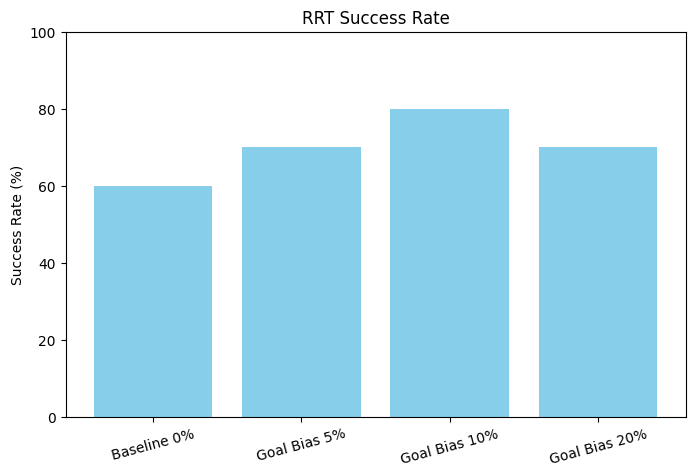

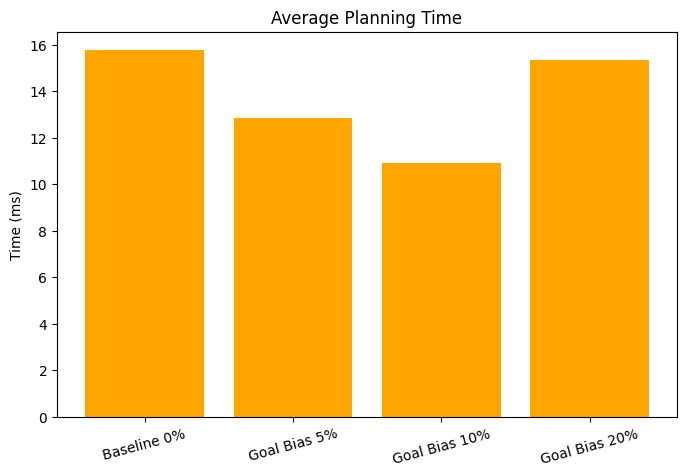

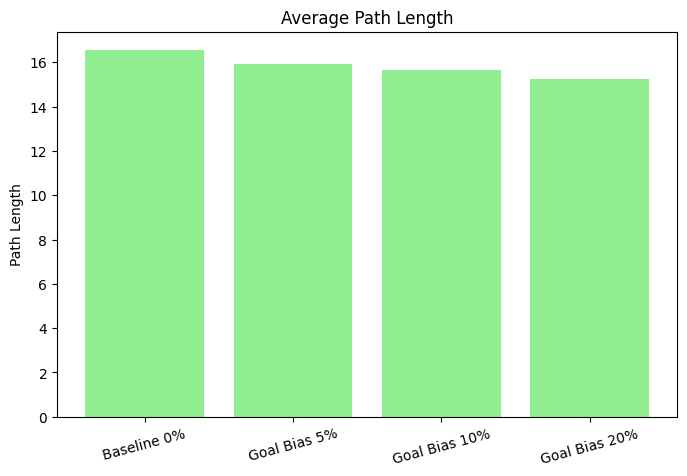

In [87]:
import matplotlib.pyplot as plt

rrt_versions = {
    "Baseline 0%": rrt_results_3,
    "Goal Bias 5%": goal_bias_5_results_3,
    "Goal Bias 10%": goal_bias_results_3,
    "Goal Bias 20%": goal_bias_20_results_3
}

names = []
success_rates = []
planning_times = []
path_lengths = []

for name, results in rrt_versions.items():
    names.append(name)

    successful_runs = [result for result in results if result["success"]]

    success_rate = len(successful_runs) / len(results) * 100
    success_rates.append(success_rate)

    average_time = sum(result["time_ms"] for result in results) / len(results)
    planning_times.append(average_time)

    average_path = sum(result["path_length"] for result in successful_runs) / len(successful_runs)
    path_lengths.append(average_path)

# Graph 1: Success Rate
plt.figure(figsize=(8, 5))
plt.bar(names, success_rates, color="skyblue")
plt.title("RRT Success Rate")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()

# Graph 2: Planning Time
plt.figure(figsize=(8, 5))
plt.bar(names, planning_times, color="orange")
plt.title("Average Planning Time")
plt.ylabel("Time (ms)")
plt.xticks(rotation=15)
plt.show()

# Graph 3: Path Length
plt.figure(figsize=(8, 5))
plt.bar(names, path_lengths, color="lightgreen")
plt.title("Average Path Length")
plt.ylabel("Path Length")
plt.xticks(rotation=15)
plt.show()

In [88]:
import pandas as pd

comparison_data = {
    "Algorithm": [
        "A*",
        "RRT Baseline",
        "RRT Goal Bias 5%",
        "RRT Goal Bias 10%",
        "RRT Goal Bias 20%"
    ],
    "Success Rate (%)": [
        100, 60, 70, 80, 70
    ],
    "Average Planning Time (ms)": [
        0.220, 15.76, 12.84, 10.91, 15.34
    ],
    "Average Path Length": [
        18.00, 16.55, 15.92, 15.64, 15.23
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("A* and RRT Comparison on Map 3")
display(comparison_df)

A* and RRT Comparison on Map 3


,Algorithm,Success Rate (%),Average Planning Time (ms),Average Path Length
0,A*,100,0.22,18.00
1,RRT Baseline,60,15.76,16.55
2,RRT Goal Bias 5%,70,12.84,15.92
3,RRT Goal Bias 10%,80,10.91,15.64
4,RRT Goal Bias 20%,70,15.34,15.23


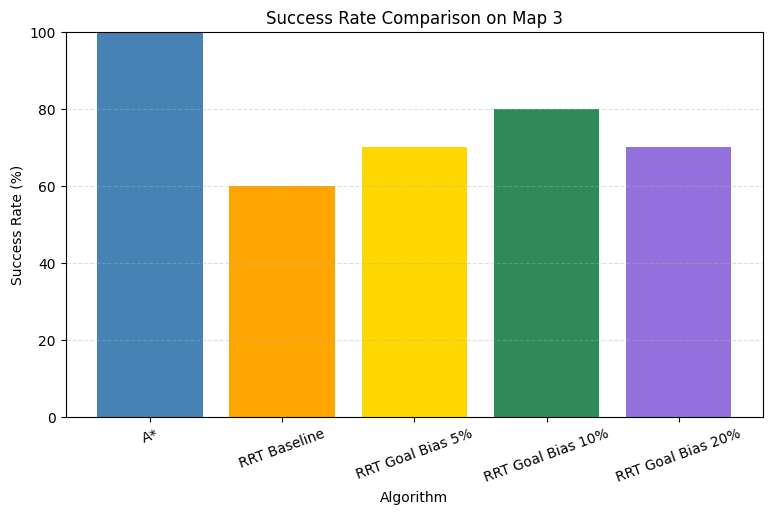

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Success Rate (%)"],
    color=["steelblue", "orange", "gold", "seagreen", "mediumpurple"]
)

plt.title("Success Rate Comparison on Map 3")
plt.xlabel("Algorithm")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

The A* algorithm achieved a 100% success rate across 10 trials. The baseline RRT achieved 60%, while RRT with goal bias values of 5%, 10%, and 20% achieved 70%, 80%, and 70%, respectively.
Among the tested RRT configurations, a 10% goal bias produced the highest success rate. This suggests that directing some random samples toward the goal can improve RRT performance in this environment. However, A* remained the most reliable algorithm in these experiments.

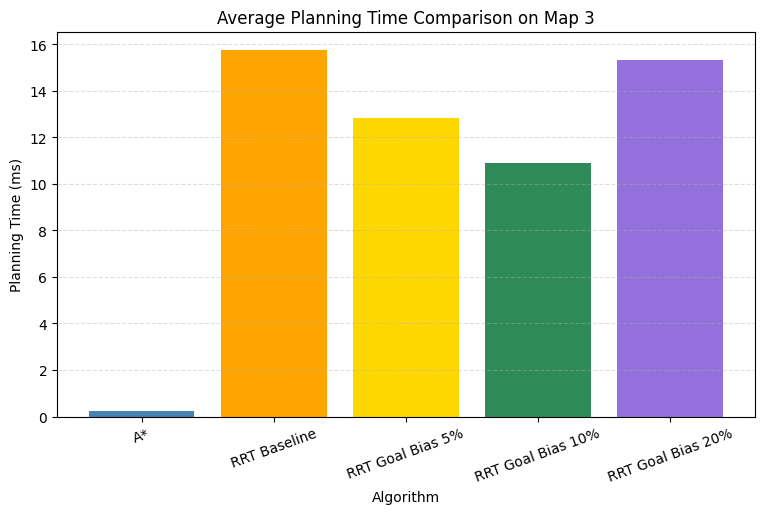

In [90]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Average Planning Time (ms)"],
    color=["steelblue", "orange", "gold", "seagreen", "mediumpurple"]
)

plt.title("Average Planning Time Comparison on Map 3")
plt.xlabel("Algorithm")
plt.ylabel("Planning Time (ms)")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

The A* algorithm demonstrated the lowest average planning time at 0.22 ms. In comparison, the baseline RRT required 15.76 ms. RRT with goal bias values of 5%, 10%, and 20% required 12.84 ms, 10.91 ms, and 15.34 ms, respectively.

Among the tested RRT configurations, a 10% goal bias achieved the shortest average planning time. However, all RRT configurations required more planning time than A* in this experiment.

These results suggest that A* was computationally faster in the tested static grid environment. Goal bias improved the planning time of RRT compared with the baseline configuration at 5% and 10%, but the 20% configuration did not provide the same improvement.

The results are preliminary and depend on the map, implementation, and experimental settings.

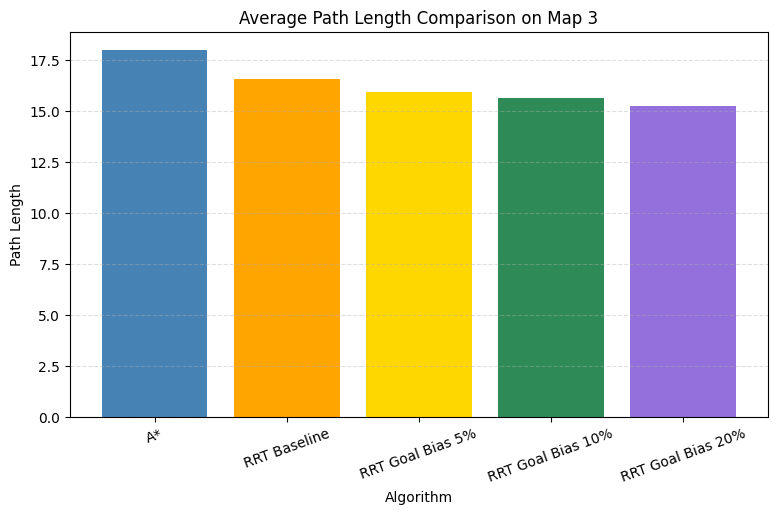

In [91]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Average Path Length"],
    color=["steelblue", "orange", "gold", "seagreen", "mediumpurple"]
)

plt.title("Average Path Length Comparison on Map 3")
plt.xlabel("Algorithm")
plt.ylabel("Path Length")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

Among the tested RRT configurations, the 20% goal bias achieved the shortest average path length of 15.23 units. The 10% goal bias produced an average path length of 15.64 units, followed by 5% goal bias at 15.92 units. The baseline RRT produced the longest average path length of 16.55 units.

These results suggest that increasing the goal bias helped RRT generate shorter paths in this environment. However, the 20% goal bias had a lower success rate (70%) than the 10% configuration (80%).
Therefore, the 10% goal bias provided a better balance between success rate, planning time, and path length among the tested configurations. These findings are preliminary and are based on 10 trials per configuration.

In [92]:
import pandas as pd

comparison_map_2 = {
    "Algorithm": [
        "A*",
        "RRT Baseline"
    ],
    "Success Rate (%)": [
        100,
        100
    ],
    "Average Planning Time (ms)": [
        0.145,
        7.65
    ],
    "Average Path Length": [
        18.00,
        19.05
    ],
    "Average Explored Nodes / Tree Nodes": [
        37,
        176.8
    ]
}

comparison_df_2 = pd.DataFrame(comparison_map_2)

print("A* and RRT Comparison on Map 2")
display(comparison_df_2)

A* and RRT Comparison on Map 2


,Algorithm,Success Rate (%),Average Planning Time (ms),Average Path Length,Average Explored Nodes / Tree Nodes
0,A*,100,0.145,18.00,37.0
1,RRT Baseline,100,7.650,19.05,176.8


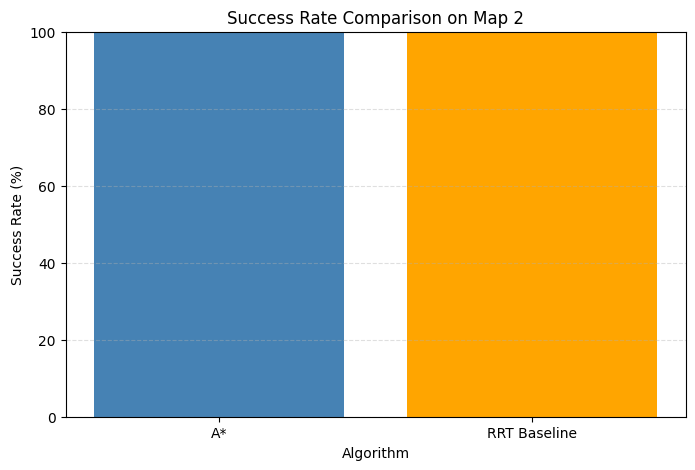

In [93]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df_2["Algorithm"],
    comparison_df_2["Success Rate (%)"],
    color=["steelblue", "orange"]
)

plt.title("Success Rate Comparison on Map 2")
plt.xlabel("Algorithm")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

Both A* and the baseline RRT algorithm achieved a 100% success rate across 10 trials. This indicates that both algorithms successfully found a path from the start position to the goal position in every trial on Map 2.
Unlike the results on Map 3, where the baseline RRT had a lower success rate, both algorithms demonstrated reliable performance in this environment.
These results suggest that the difficulty of the environment can influence RRT performance. However, further testing with additional maps and more trials is required to confirm this observation.

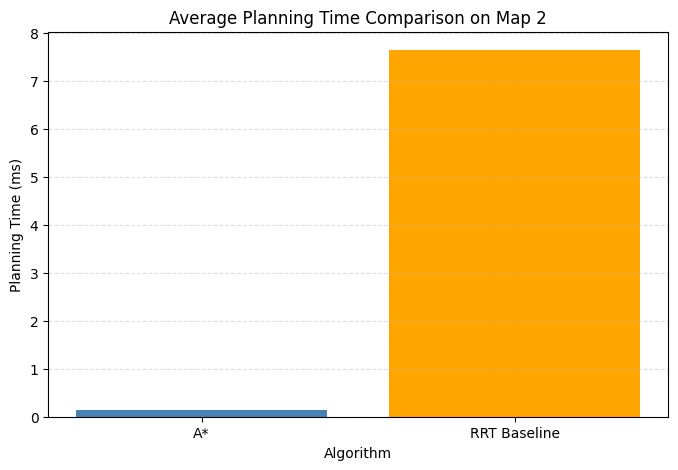

In [94]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df_2["Algorithm"],
    comparison_df_2["Average Planning Time (ms)"],
    color=["steelblue", "orange"]
)

plt.title("Average Planning Time Comparison on Map 2")
plt.xlabel("Algorithm")
plt.ylabel("Planning Time (ms)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

The A* algorithm achieved an average planning time of 0.145 ms, while the baseline RRT required 7.65 ms across 10 trials.
In this experiment, A* planned a path approximately 53 times faster than RRT. Both algorithms achieved a 100% success rate, but A* demonstrated significantly lower computational time.
These results indicate that A* was more computationally efficient than the baseline RRT in the tested static grid environment. However, this result is specific to the current map and implementation and should not be generalized to all navigation environments.

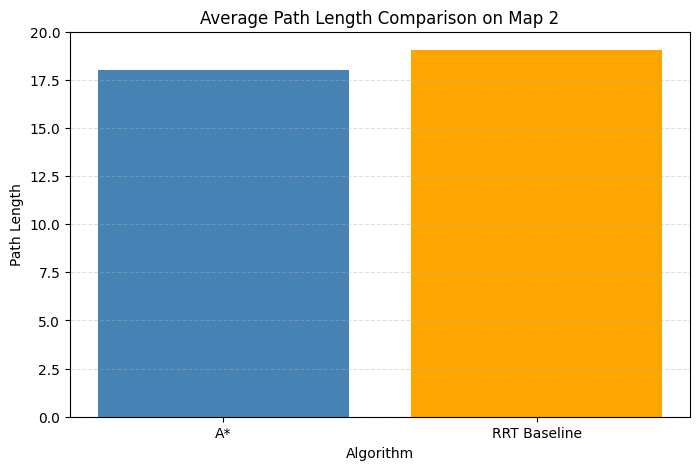

In [95]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df_2["Algorithm"],
    comparison_df_2["Average Path Length"],
    color=["steelblue", "orange"]
)

plt.title("Average Path Length Comparison on Map 2")
plt.xlabel("Algorithm")
plt.ylabel("Path Length")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

The A* algorithm produced an average path length of 18 grid steps, while the baseline RRT generated an average path length of 19.05 geometric units across 10 successful trials.
Both algorithms successfully reached the goal in all 10 trials. However, the path length values are calculated using different measurement methods: A* uses discrete grid steps, whereas RRT uses Euclidean distance.
Therefore, these values should not be directly compared. A common path-length measurement method will be required for a fair comparison in future experiments.

In [96]:
import pandas as pd

overall_results = {
    "Map": [
        "Map 2",
        "Map 2",
        "Map 3",
        "Map 3",
        "Map 3",
        "Map 3",
        "Map 3"
    ],

    "Algorithm": [
        "A*",
        "RRT Baseline",
        "A*",
        "RRT Baseline",
        "RRT Goal Bias 5%",
        "RRT Goal Bias 10%",
        "RRT Goal Bias 20%"
    ],

    "Success Rate (%)": [
        100, 100, 100, 60, 70, 80, 70
    ],

    "Average Planning Time (ms)": [
        0.145, 7.65, 0.220, 15.76, 12.84, 10.91, 15.34
    ],

    "Average Path Length": [
        18.00, 19.05, 18.00, 16.55, 15.92, 15.64, 15.23
    ],

    "Number of Trials": [
        10, 10, 10, 10, 10, 10, 10
    ]
}

overall_df = pd.DataFrame(overall_results)

print("Overall A* and RRT Experimental Results")
display(overall_df)

Overall A* and RRT Experimental Results


,Map,Algorithm,Success Rate (%),Average Planning Time (ms),Average Path Length,Number of Trials
0,Map 2,A*,100,0.145,18.00,10
1,Map 2,RRT Baseline,100,7.650,19.05,10
2,Map 3,A*,100,0.220,18.00,10
3,Map 3,RRT Baseline,60,15.760,16.55,10
4,Map 3,RRT Goal Bias 5%,70,12.840,15.92,10
5,Map 3,RRT Goal Bias 10%,80,10.910,15.64,10
6,Map 3,RRT Goal Bias 20%,70,15.340,15.23,10


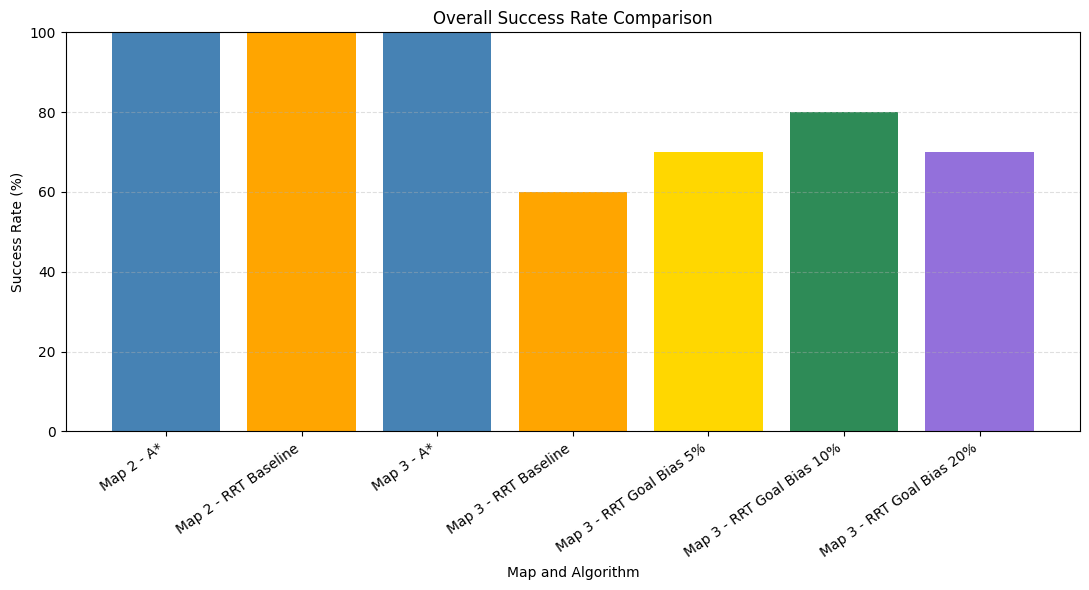

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

labels = overall_df["Map"] + " - " + overall_df["Algorithm"]

plt.bar(
    labels,
    overall_df["Success Rate (%)"],
    color=[
        "steelblue", "orange",
        "steelblue", "orange",
        "gold", "seagreen", "mediumpurple"
    ]
)

plt.title("Overall Success Rate Comparison")
plt.xlabel("Map and Algorithm")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

The A* algorithm achieved a 100% success rate on both Map 2 and Map 3 across 10 trials per map. The baseline RRT also achieved 100% success on Map 2, but its success rate decreased to 60% on Map 3.

On Map 3, introducing goal bias improved RRT performance. A 5% goal bias achieved a 70% success rate, while 10% achieved the highest rate of 80%. Increasing the goal bias to 20% resulted in a 70% success rate.

These findings indicate that RRT performance was more sensitive to the tested environment and parameter settings. A* demonstrated consistent reliability across both tested maps. However, these results are preliminary and based on a limited number of trials.

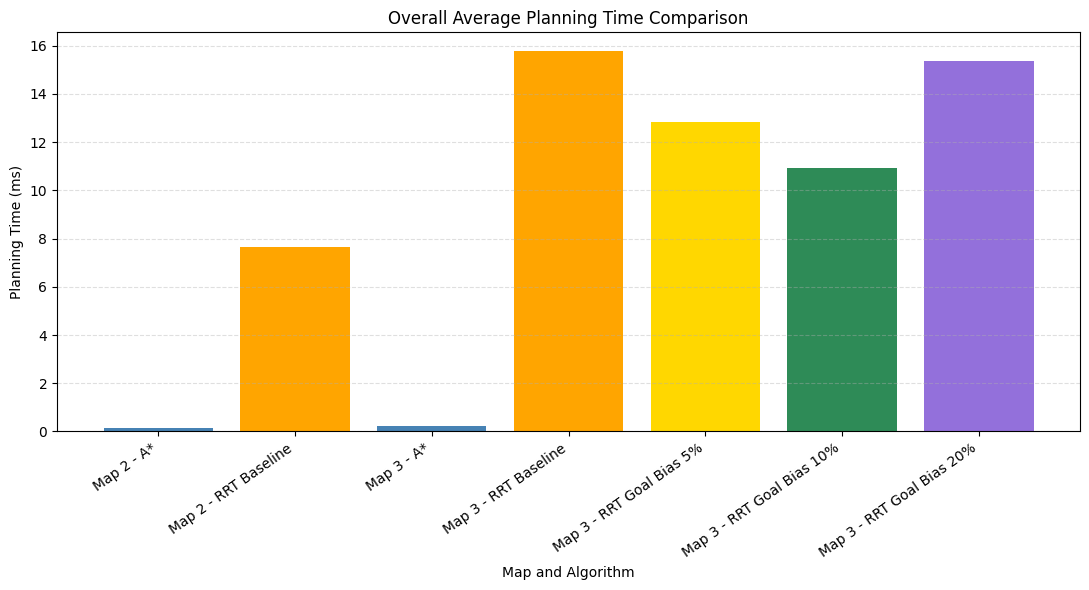

In [98]:
plt.figure(figsize=(11, 6))

labels = overall_df["Map"] + " - " + overall_df["Algorithm"]

plt.bar(
    labels,
    overall_df["Average Planning Time (ms)"],
    color=[
        "steelblue", "orange",
        "steelblue", "orange",
        "gold", "seagreen", "mediumpurple"
    ]
)

plt.title("Overall Average Planning Time Comparison")
plt.xlabel("Map and Algorithm")
plt.ylabel("Planning Time (ms)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

The A* algorithm demonstrated the lowest average planning time on both maps, requiring 0.145 ms on Map 2 and 0.220 ms on Map 3.

The baseline RRT required 7.65 ms on Map 2 and 15.76 ms on Map 3. On Map 3, goal bias reduced the average planning time to 12.84 ms (5%), 10.91 ms (10%), and 15.34 ms (20%).
Among the tested RRT configurations, a 10% goal bias achieved the lowest average planning time on Map 3. However, A* remained substantially faster in both tested environments.
These results suggest that A* was more computationally efficient in our static grid experiments. RRT planning time was more variable and appeared sensitive to map complexity and goal bias settings.

In [99]:
import pandas as pd

collision_data = {
    "Map": [
        "Map 2",
        "Map 2",
        "Map 3",
        "Map 3",
        "Map 3",
        "Map 3",
        "Map 3"
    ],
    "Algorithm": [
        "A*",
        "RRT Baseline",
        "A*",
        "RRT Baseline",
        "RRT Goal Bias 5%",
        "RRT Goal Bias 10%",
        "RRT Goal Bias 20%"
    ],
    "Successful Paths": [
        10, 10, 10, 6, 7, 8, 7
    ],
    "Collision-Free Paths": [
        10, 10, 10, 6, 7, 8, 7
    ],
    "Collision-Free Rate (%)": [
        100, 100, 100, 100, 100, 100, 100
    ]
}

collision_df = pd.DataFrame(collision_data)

print("Collision-Free Performance")
display(collision_df)

Collision-Free Performance


,Map,Algorithm,Successful Paths,Collision-Free Paths,Collision-Free Rate (%)
0,Map 2,A*,10,10,100
1,Map 2,RRT Baseline,10,10,100
2,Map 3,A*,10,10,100
3,Map 3,RRT Baseline,6,6,100
4,Map 3,RRT Goal Bias 5%,7,7,100
5,Map 3,RRT Goal Bias 10%,8,8,100
6,Map 3,RRT Goal Bias 20%,7,7,100


In [100]:
import pandas as pd
from google.colab import files

# Create an Excel file with separate sheets
with pd.ExcelWriter("Drone_Navigation_Experimental_Results.xlsx") as writer:

    overall_df.to_excel(
        writer,
        sheet_name="Overall Results",
        index=False
    )

    collision_df.to_excel(
        writer,
        sheet_name="Collision-Free Results",
        index=False
    )

    comparison_df_2.to_excel(
        writer,
        sheet_name="Map 2 Comparison",
        index=False
    )

    comparison_df.to_excel(
        writer,
        sheet_name="Map 3 Comparison",
        index=False
    )

print("Results exported successfully!")

files.download("Drone_Navigation_Experimental_Results.xlsx")

Results exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>